# AI in Healthcare — Lab Assignment 7



In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

from scikeras.wrappers import KerasClassifier

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# The CSV is expected to be in the same folder as this notebook.
# Search the current working directory and its parent folders.
csv_name = "pima-indians-diabetes.csv"
DATA_PATH = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / csv_name
    if candidate.is_file():
        DATA_PATH = candidate
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {csv_name!r}. Place it in the same folder as the "
        "notebook, or update DATA_PATH to its full path. "
        f"Notebook working directory: {Path.cwd()}"
    )

# This Pima CSV has NO header row. Assign the correct column names explicitly.
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(DATA_PATH, header=None, names=column_names)

# Validate the loaded file before continuing.
if df.shape[1] != 9:
    raise ValueError(
        f"Expected 9 columns in the Pima dataset, but found {df.shape[1]}."
    )

df = df.apply(pd.to_numeric, errors="raise")

print("Dataset loaded successfully!")
print("CSV path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
CSV path: /run/media/sambhav/New Volume/Documents/UNI/4th year/Ai in Healthcare/ CSET343 Ai in  Healthcare/LAB 7/pima-indians-diabetes.csv
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Task 1 — Data Acquisition and Loading

The notebook expects the standard Pima Indians Diabetes CSV, generally containing the clinical input columns and an `Outcome` target column.


In [10]:
print("Columns:")
print(df.columns.tolist())

print("\\nMissing values:")
print(df.isnull().sum())

print("\\nClass distribution:")
print(df["Outcome"].value_counts().sort_index())

print("\\nClass distribution percentage:")
print((df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\\nDataset summary:")
display(df.describe())


Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
\nMissing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
\nClass distribution:
Outcome
0    500
1    268
Name: count, dtype: int64
\nClass distribution percentage:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64
\nDataset summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [11]:
# Separate the eight input features from the target column.
X = df.drop(columns=["Outcome"])
y = df["Outcome"].astype("int32")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of input features:", X_train.shape[1])


Training samples: 614
Testing samples: 154
Number of input features: 8


## Task 2 — Data Preprocessing

Feature scaling is important for neural networks because the input variables have different numerical ranges.

`StandardScaler` transforms each feature approximately as:

**z = (x − mean) / standard deviation**


In [12]:
# Build the Keras model

def create_model(
    learning_rate=0.001,
    init_mode="uniform",
    activation="relu",
    dropout_rate=0.0,
    neurons=16
):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(8,)),
        tf.keras.layers.Dense(
            neurons,
            kernel_initializer=init_mode,
            activation=activation
        ),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(
            1,
            kernel_initializer=init_mode,
            activation="sigmoid"
        )
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


## Task 3 — Deep Learning Grid Search

`GridSearchCV` tests combinations of the supplied hyperparameter values.

To keep the lab practical on a normal laptop, the grid below is deliberately small. You can expand it if your instructor requires a larger search.


In [13]:
keras_model = KerasClassifier(
    model=create_model,
    verbose=0,
    random_state=SEED
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", keras_model)
])

param_grid = {
    "model__batch_size": [16, 32],
    "model__epochs": [20, 40],
    "model__model__learning_rate": [0.001, 0.0001],
    "model__model__init_mode": ["uniform", "glorot_uniform"],
    "model__model__activation": ["relu", "tanh"],
    "model__model__dropout_rate": [0.0, 0.3],
    "model__model__neurons": [16, 32]
}

print("Total possible combinations:", np.prod([
    len(v) for v in param_grid.values()
]))


Total possible combinations: 128


In [ ]:

small_param_grid = {
    "model__batch_size": [16, 32],
    "model__epochs": [20],
    "model__model__learning_rate": [0.001, 0.0001],
    "model__model__init_mode": ["uniform", "glorot_uniform"],
    "model__model__activation": ["relu", "tanh"],
    "model__model__dropout_rate": [0.0, 0.3],
    "model__model__neurons": [16, 32]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=small_param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=1,
    verbose=2
)

grid_result = grid.fit(X_train, y_train)

print("\nBest CV Accuracy:", grid_result.best_score_)
print("\nBest Parameters:")
print(grid_result.best_params_)


In [19]:
# Display GridSearchCV results using the actual SciKeras-routed parameter names.
cv_results = pd.DataFrame(grid_result.cv_results_)

base_columns = [
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]

# With a Pipeline step named "model" and SciKeras model-builder arguments,
# the result columns include the nested model__model__ prefix.
parameter_columns = [
    "param_model__batch_size",
    "param_model__epochs",
    "param_model__model__learning_rate",
    "param_model__model__init_mode",
    "param_model__model__activation",
    "param_model__model__dropout_rate",
    "param_model__model__neurons",
]

# Keep only columns that are actually present, preventing KeyError if the
# parameter grid is adjusted later.
columns_to_show = [
    col for col in base_columns + parameter_columns
    if col in cv_results.columns
]

print("Available GridSearchCV result columns:")
print(cv_results.columns.tolist())

print("\\nTop 10 parameter combinations:")
display(
    cv_results[columns_to_show]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
)


Available GridSearchCV result columns:
['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_model__batch_size', 'param_model__epochs', 'param_model__model__activation', 'param_model__model__dropout_rate', 'param_model__model__init_mode', 'param_model__model__learning_rate', 'param_model__model__neurons', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
\nTop 10 parameter combinations:


,mean_test_score,std_test_score,rank_test_score,param_model__batch_size,param_model__epochs,param_model__model__learning_rate,param_model__model__init_mode,param_model__model__activation,param_model__model__dropout_rate,param_model__model__neurons
16,0.778519,0.007821,1,16,20,0.001,uniform,tanh,0.0,16
21,0.775275,0.013906,2,16,20,0.001,glorot_uniform,tanh,0.0,32
25,0.775267,0.010062,3,16,20,0.001,uniform,tanh,0.3,32
17,0.775267,0.010062,3,16,20,0.001,uniform,tanh,0.0,32
1,0.773649,0.014610,5,16,20,0.001,uniform,relu,0.0,32
29,0.773649,0.014610,5,16,20,0.001,glorot_uniform,tanh,0.3,32
53,0.773641,0.011013,7,32,20,0.001,glorot_uniform,tanh,0.0,32
61,0.773641,0.011013,7,32,20,0.001,glorot_uniform,tanh,0.3,32
24,0.773633,0.007811,9,16,20,0.001,uniform,tanh,0.3,16
33,0.770405,0.020622,10,32,20,0.001,uniform,relu,0.0,32


In [17]:
# Final evaluation on the held-out test set

best_model = grid_result.best_estimator_

y_pred = best_model.predict(X_test)
y_pred = np.asarray(y_pred).astype(int).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Test Accuracy :", accuracy)
print("Test Precision:", precision)
print("Test Recall   :", recall)
print("Test F1-score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Test Accuracy : 0.7207792207792207
Test Precision: 0.6170212765957447
Test Recall   : 0.5370370370370371
Test F1-score : 0.5742574257425742

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.82      0.79       100
           1       0.62      0.54      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.68      0.68       154
weighted avg       0.71      0.72      0.72       154



E0000 00:00:1793545686.969528   62237 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


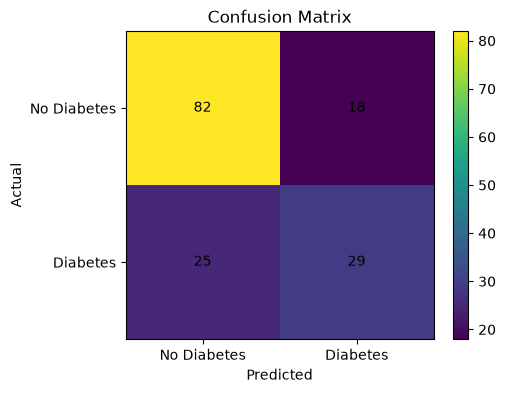

In [18]:
# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])
plt.show()


## Viva Points

### What is Grid Search?
Grid Search is an exhaustive method that evaluates predefined combinations of hyperparameters and selects the combination giving the best cross-validation score.

### What is cross-validation?
The training data is divided into folds. The model is trained on some folds and validated on the remaining fold, repeating this process so every fold is used for validation.

### Why StandardScaler?
It puts features on a comparable scale, which generally makes neural-network optimization more stable.

### Why learning rate?
It controls the step size used by the optimizer when updating model weights.

### Why batch size?
It determines how many training examples are processed before one weight update.

### Why epochs?
One epoch means one complete pass through the training data.

### Why dropout?
Dropout randomly removes a fraction of neurons during training to reduce overfitting.

### Why activation functions?
They introduce non-linearity, allowing the neural network to learn complex relationships.

### Why weight initialization?
Initial weights affect the starting point of optimization and can influence convergence.

### Hidden-layer neurons
More neurons increase model capacity but may increase computation and overfitting risk.

### Important formulas

**Binary Cross-Entropy:**

`Loss = -[y log(p) + (1-y) log(1-p)]`

**Accuracy:**

`(TP + TN) / (TP + TN + FP + FN)`

**Precision:**

`TP / (TP + FP)`

**Recall:**

`TP / (TP + FN)`

**F1-score:**

`2 × Precision × Recall / (Precision + Recall)`
